In [1]:
import periapsis as p
import numpy as np
import pandas as pd
import astropy.units as u

# 51 Pegasi b (HD 217014)
> First discovered hot Jupiter orbiting a sun like star (Mayor & Queloz (1995)).


> Data taken from corrected radial velocity catalog of exoplanets from Lick Observatory (Tal-Or et al. (2019)). Original catalog provided by Butler et al. (2017). 

> See Table 3 of Bulter et al. (2017) for literature orbital fit parameters

In [2]:
df = pd.read_csv('data/51Peg/51peg.tsv', comment='#', sep=r'\s+')

In [3]:
#remove top two rows that are not data
df = df.iloc[2:] 

obs = pd.to_numeric(df['BJD'], errors='coerce').to_numpy()
obs_days = obs - 2450000 #days since JD 2450000
ref_epoch = np.mean(obs_days) #mean epoch of observations

rv = pd.to_numeric(df['RVcor'], errors='coerce').to_numpy() #m/s
rv_err = pd.to_numeric(df['e_RVcor'], errors='coerce').to_numpy() #m/s

M1 = 1.09 #mass of 51 Peg in Msun


Start with a quick MCMCLinearFitter fit

In [4]:
units = {'t':'day', 'rv':'m/s','rv_err':'m/s'}
rv_data = p.RadialVelocityData(obs_days, rv, rv_err,units=units, system =1)

In [5]:
priors_lin = {'P' : p.UniformPrior(0.5,10), #days, same as time units of data
              'e': p.LogUniformPrior(1e-4, 0.9),
              't0': p.UniformPrior(-0.5,0.5),
              'M1': p.FixedPrior(M1,unit='Msun'),}

fit1 = p.MCMCLinearFitter(nwalkers=30,niter=10000,sampled_params=['P','e','t0'],**priors_lin)

results1 = fit1.fit(rv_data,np.random.default_rng(51)) 

ASSUMPTION: Assuming prior on 'P' is in units of d. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'Tepoch' is in units of d. To suppress this warning, explicitly set the unit on the prior.


100%|██████████| 10000/10000 [00:55<00:00, 179.00it/s]


In [6]:
results1

### Fit Results (linear emcee on RadialVelocityData)

$\chi^2_{\rm red., med} = 6.317760$, $\chi^2_{\rm red., MAP} = 6.315947$

(40 degrees of freedom)

#### Parameters and Uncertainties

| Parameter | Median (1-$\sigma$) | MAP | Unit |
| :--- | :--- | :--- | :--- |
| $P$ (sampled) | $4.230803^{+0.000015}_{-0.000016}$ | $4.230804$ | $\mathrm{d}$ |
| $e$ (sampled) | $0.021^{+0.004}_{-0.004}$ | $0.021$ | $\mathrm{}$ |
| $t_0$ (sampled) | $-0.449^{+0.038}_{-0.031}$ | $-0.457$ | $\mathrm{}$ |
| ${M}_{1}$ | $1.09$ | $1.09$ | $\mathrm{M_{\odot}}$ |
| $T_\mathrm{epoch}$ | $0.0$ | $0.0$ | $\mathrm{d}$ |
| $T_p$ | $-1.90^{+0.16}_{-0.13}$ | ${\rm N/A}$ | $\mathrm{d}$ |
| $\gamma$ | $-16.33^{+0.07}_{-0.06}$ | $-16.35$ | $\mathrm{m\,s^{-1}}$ |
| ${h}_{1}$ | $-35^{+9}_{-10}$ | $-33$ | $\mathrm{m\,s^{-1}}$ |
| ${c}_{1}$ | $-44^{+10}_{-6}$ | $-46$ | $\mathrm{m\,s^{-1}}$ |

#### Other Available Parameters
Other available parameters (access with `fit_results['param_name']`): $E_0$, ${K}_{1}$, $M_0$, $a_1 \sin i$, ${f}_{1}$, ${\min M}_{2}$, $n$, $\nu_0$, $\omega$, ${\omega}_{1}$, ${\omega}_{2}$

In [7]:
results1['minM2','Mjup']

${\min M}_{2}$ Posterior Samples (n=4950):
`[0.47806551 0.4781648  0.4779537  ... 0.47818738 0.47775111 0.4774737 ]` $\mathrm{M_{\rm J}}$


Median = 0.4780724332932258 $\mathrm{M_{\rm J}}$

MAP    = 0.47811419706517355 $\mathrm{M_{\rm J}}$

1-sigma confidence interval: $0.47807^{+0.00030}_{-0.00030}$ $\mathrm{M_{\rm J}}$

2-sigma confidence interval: $0.4781^{+0.0006}_{-0.0006}$ $\mathrm{M_{\rm J}}$

3-sigma confidence interval: $0.4781^{+0.0009}_{-0.0008}$ $\mathrm{M_{\rm J}}$

> Full parameter fit 

In [8]:
priors = {
    'P': p.UniformPrior(0.5,10),
    'e': p.LogUniformPrior(1e-4, 0.9),
    't0': p.UniformPrior(-0.5,0.5),
    'Tepoch': p.FixedPrior(ref_epoch),
    'M1': p.FixedPrior(M1),
    'K1' : p.UniformPrior(0, 100),
    'omega1' : p.UniformPrior(0, 2*np.pi),
    'gamma' : p.UniformPrior(-100, 100),
    'rv_jitter' : p.LogUniformPrior(1e-4, 10),
    'dgamma' : p.UniformPrior(-10,10,),
}

fitter2 = p.MCMCFitter(nwalkers=50,niter=40000,sample_params=['P','e','t0','K1','omega1','gamma','rv_jitter','dgamma'],**priors)
results2 = fitter2.fit(rv_data,np.random.default_rng(51))

ASSUMPTION: Assuming prior on 'P' is in units of d. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'Tepoch' is in units of d. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'M1' is in units of solMass. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'K1' is in units of m / s. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'omega1' is in units of rad. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'gamma' is in units of m / s. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'rv_jitter' is in units of m / s. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'dgamma' is in units of m / (d s). To suppress this warning, explicitly set the unit on the prior.


100%|██████████| 40000/40000 [04:18<00:00, 154.73it/s]


In [9]:
results2 

### Fit Results (full emcee on RadialVelocityData)

$\chi^2_{\rm red., med} = 1.059193$, $\chi^2_{\rm red., MAP} = 1.242733$

(38 degrees of freedom)

#### Parameters and Uncertainties

| Parameter | Median (1-$\sigma$) | MAP | Unit |
| :--- | :--- | :--- | :--- |
| $P$ (sampled) | $4.23078^{+0.00004}_{-0.00004}$ | $4.23080$ | $\mathrm{d}$ |
| $e$ (sampled) | $0.07^{+0.26}_{-0.05} \times 10^{-2}$ | $0.01 \times 10^{-2}$ | $\mathrm{}$ |
| $t_0$ (sampled) | $-0.33^{+0.15}_{-0.13}$ | $-0.47$ | $\mathrm{}$ |
| ${K}_{1}$ (sampled) | $56.5^{+0.6}_{-0.6}$ | $56.7$ | $\mathrm{m\,s^{-1}}$ |
| ${\omega}_{1}$ (sampled) | $4.9^{+1.0}_{-0.8}$ | $4.0$ | $\mathrm{rad}$ |
| $\gamma$ (sampled) | $-16.3^{+0.5}_{-0.5}$ | $-16.4$ | $\mathrm{m\,s^{-1}}$ |
| $rv_jitter$ (sampled) | $2.85^{+0.40}_{-0.35}$ | $2.60$ | $\mathrm{m\,s^{-1}}$ |
| $dgamma$ (sampled) | $-1^{+5}_{-5} \times 10^{-4}$ | $-4 \times 10^{-4}$ | $\mathrm{m\,d^{-1}\,s^{-1}}$ |
| ${M}_{1}$ | $1.09$ | $1.09$ | $\mathrm{M_{\odot}}$ |
| $T_\mathrm{epoch}$ | $5264.400611304364$ | $5264.400611304364$ | $\mathrm{d}$ |

#### Other Available Parameters
Other available parameters (access with `fit_results['param_name']`): $E_0$, $M_0$, $T_p$, $a_1 \sin i$, ${c}_{1}$, ${f}_{1}$, ${h}_{1}$, ${\min M}_{2}$, $n$, $\nu_0$, $\omega$, ${\omega}_{2}$

In [10]:
_,_ = p.all_stats(results2,rv_data)

{
    "red_chi2_map": 1.2427330409448807,
    "red_chi2_med": 1.0591930990779581,
    "dof": 38,
    "uwe_map": 1.1147793687294723,
    "uwe_med": 1.02917107376663,
    "delta_chi2_map": 63026.55334151917,
    "delta_chi2_med": 63033.52785931012,
    "p_value_map": 0.0,
    "p_value_med": 0.0,
    "sigma_significance": 6643.816469268022,
    "sampled_params": [
        "P",
        "e",
        "t0",
        "K1",
        "omega1",
        "gamma",
        "rv_jitter",
        "dgamma"
    ],
    "Ess": [
        14259.363126653052,
        5786.716259704375,
        9727.629044829526,
        13346.458370067143,
        9729.736231526054,
        13350.892640475255,
        12577.276716209084,
        13844.189142629586
    ],
    "mean_acceptance_fraction": 0.3468834999999999,
    "tau": [
        140.25871858622332,
        345.6191577815798,
        205.59994534979202,
        149.8524885437408,
        205.55541819516634,
        149.80271760531554,
        159.01693547240487,
   

In [11]:
results2['minM2','Mjup']

${\min M}_{2}$ Posterior Samples (n=7000):
`[0.47179803 0.47619508 0.4799113  ... 0.47888532 0.48786479 0.47718114]` $\mathrm{M_{\rm J}}$


Median = 0.476576266044604 $\mathrm{M_{\rm J}}$

MAP    = 0.4777368984359693 $\mathrm{M_{\rm J}}$

1-sigma confidence interval: $0.477^{+0.005}_{-0.005}$ $\mathrm{M_{\rm J}}$

2-sigma confidence interval: $0.477^{+0.011}_{-0.011}$ $\mathrm{M_{\rm J}}$

3-sigma confidence interval: $0.477^{+0.016}_{-0.016}$ $\mathrm{M_{\rm J}}$

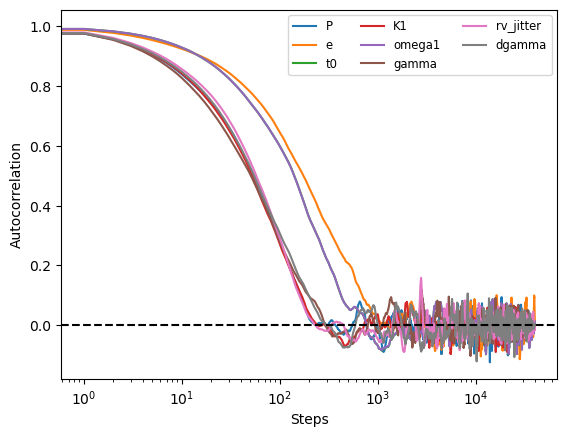

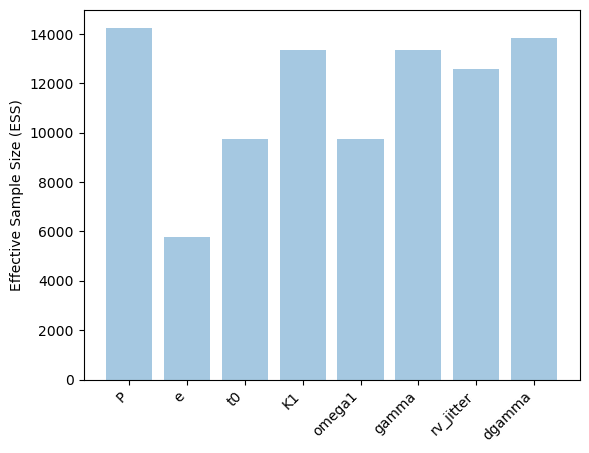

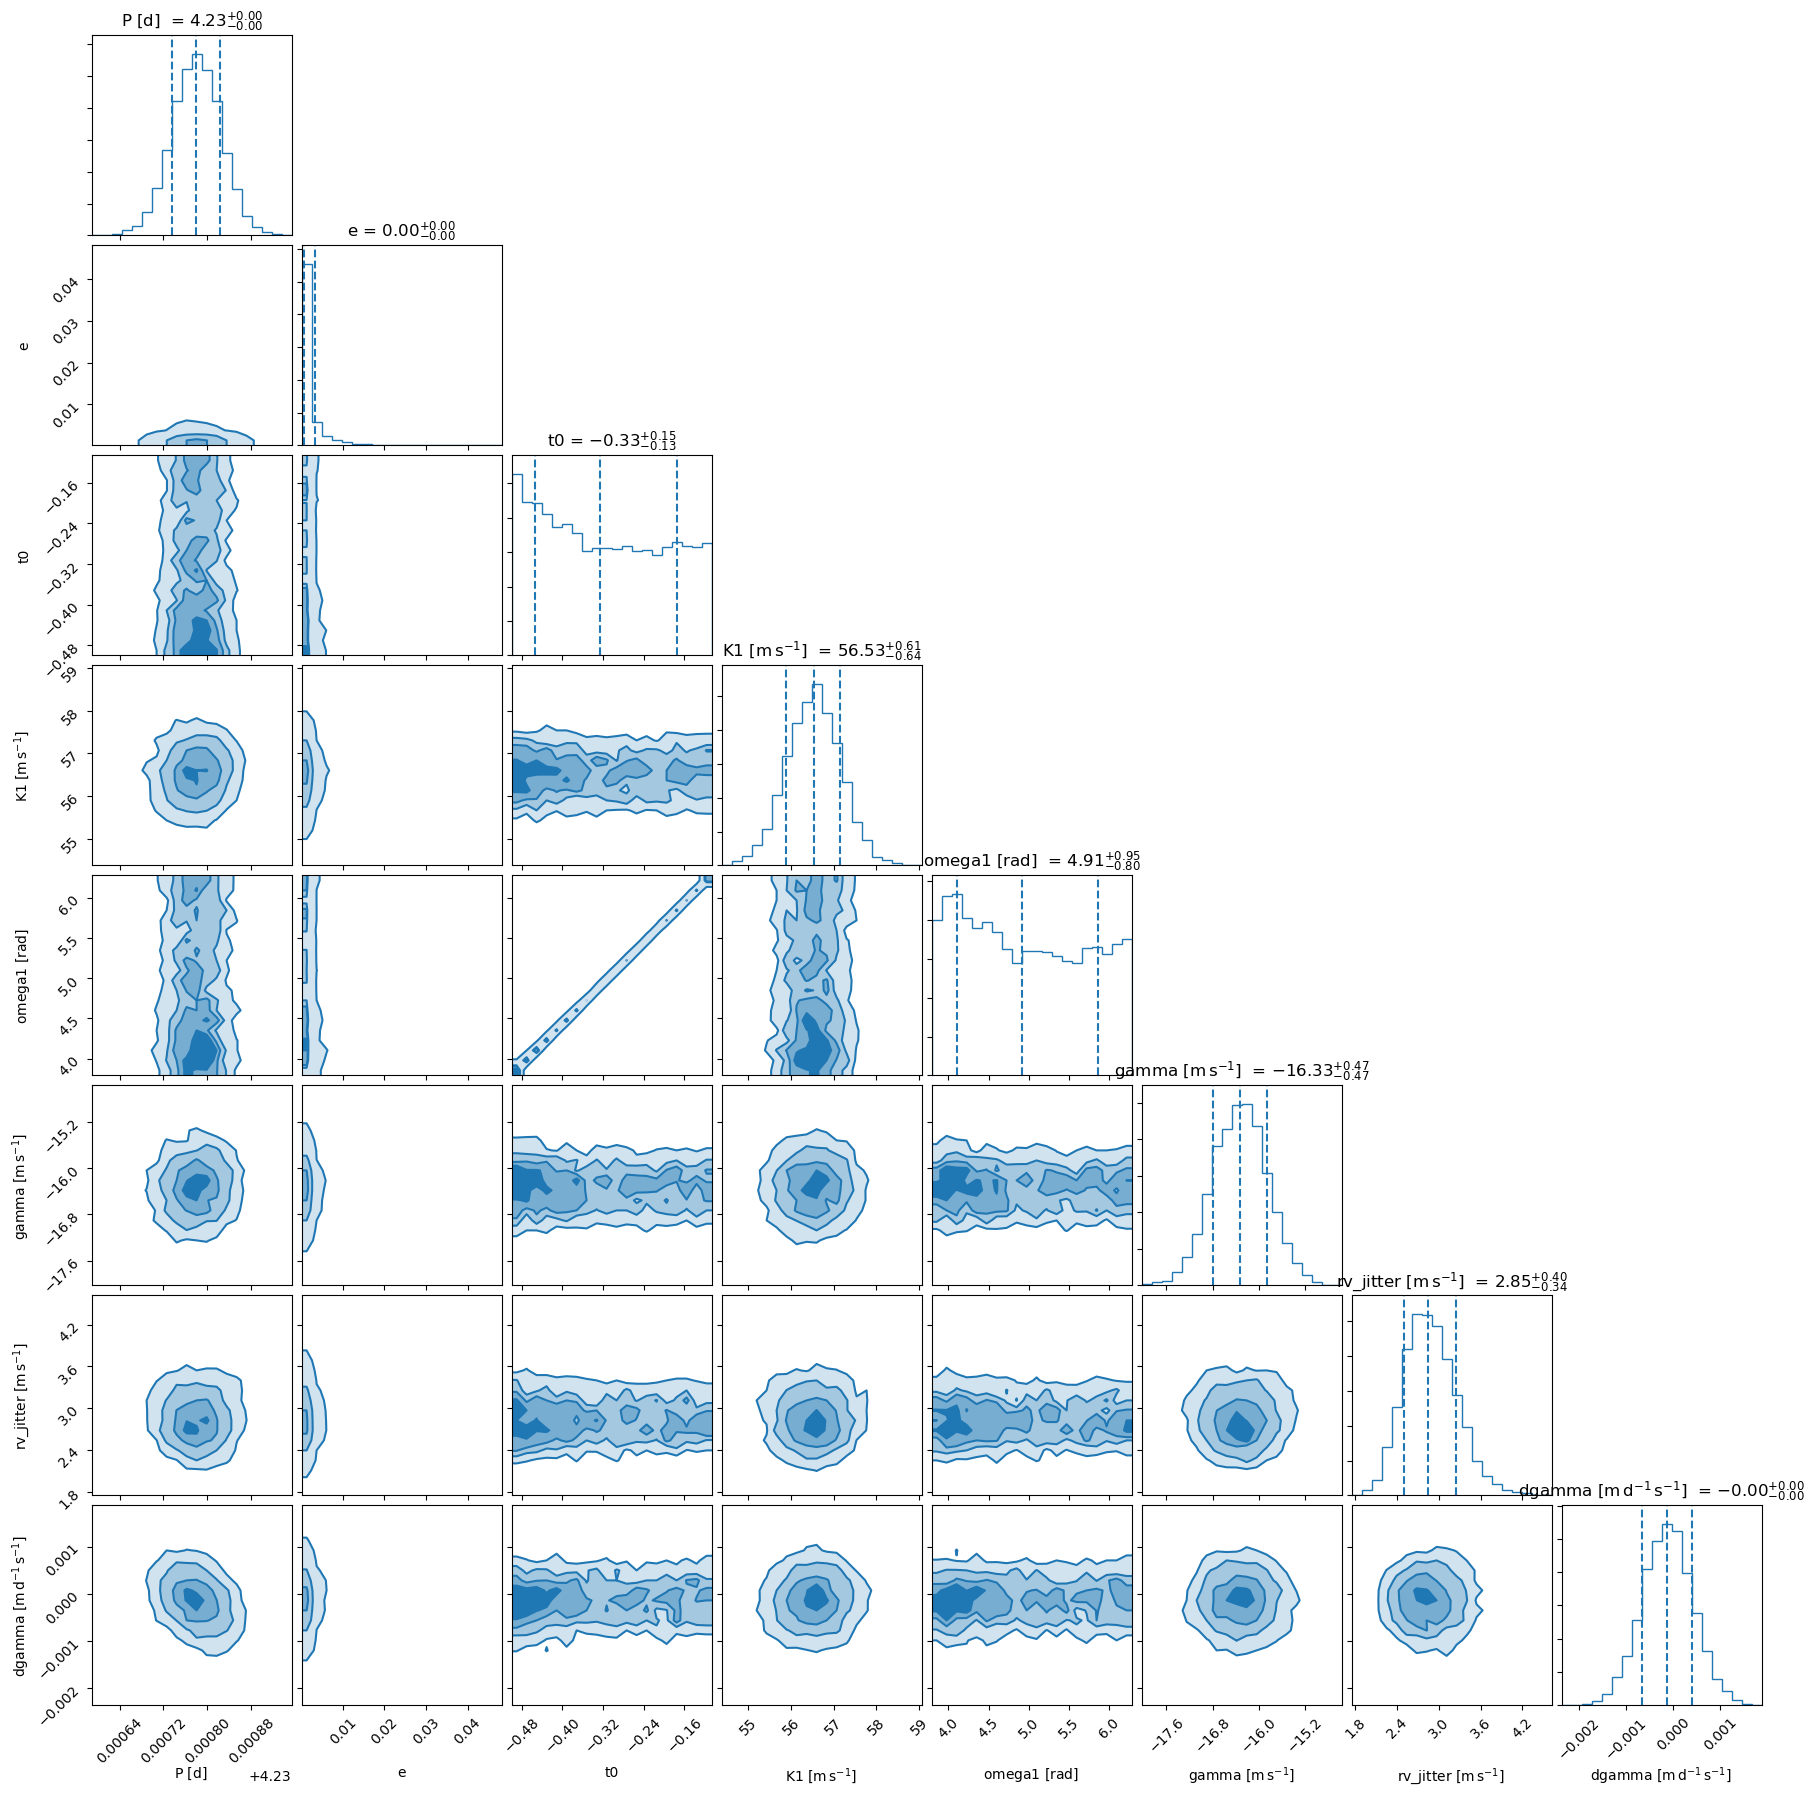

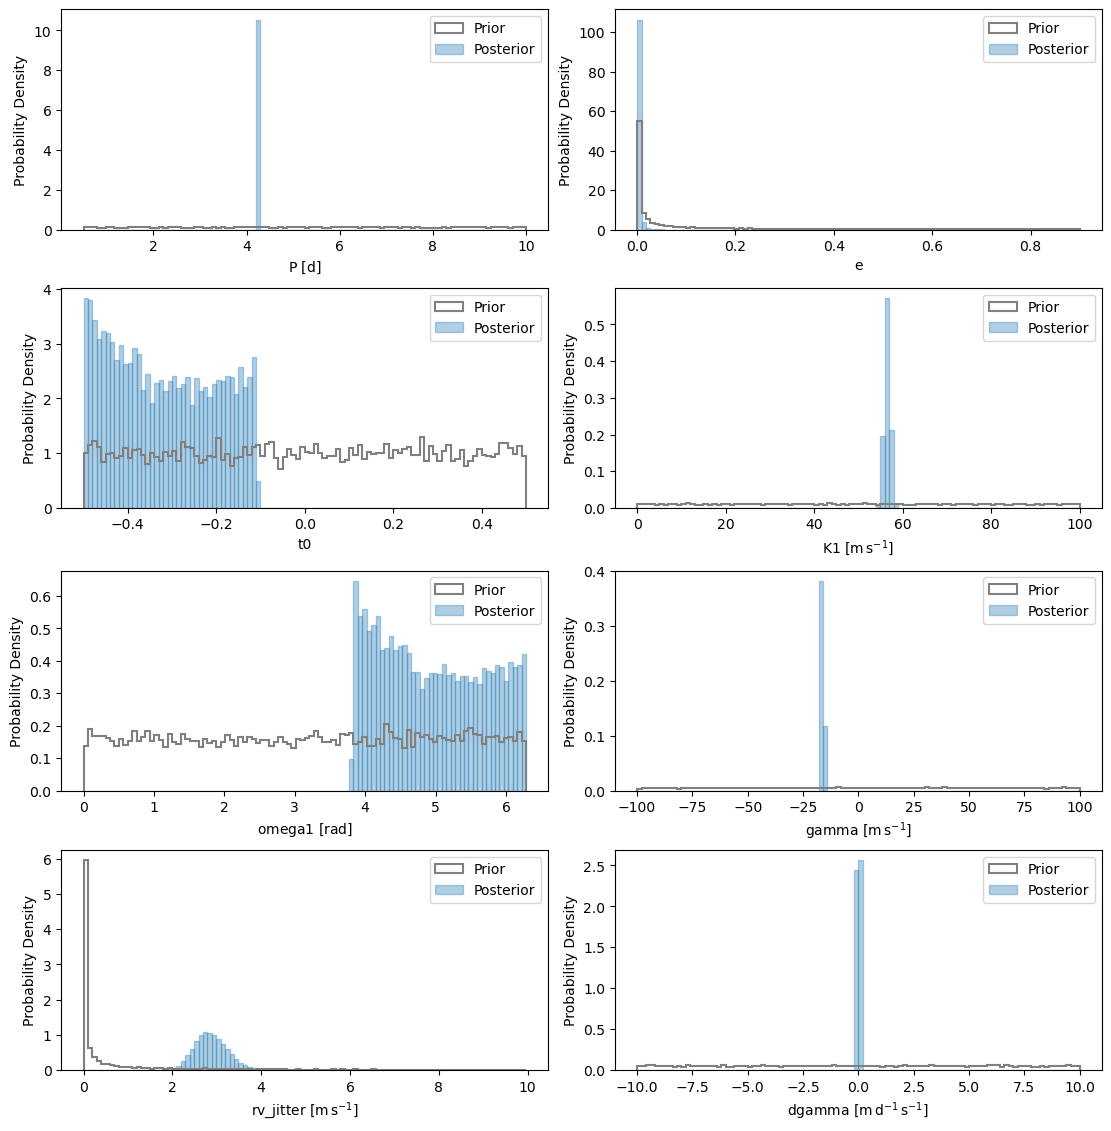

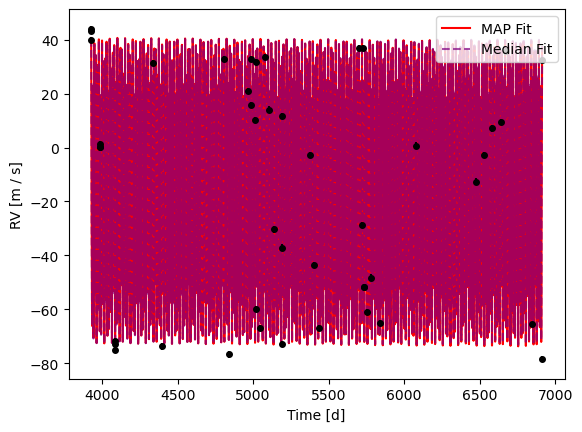

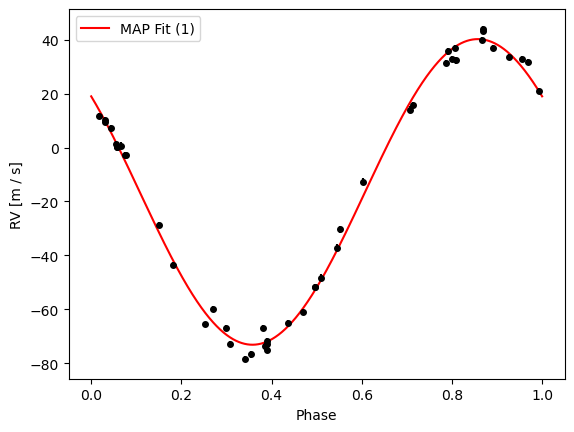

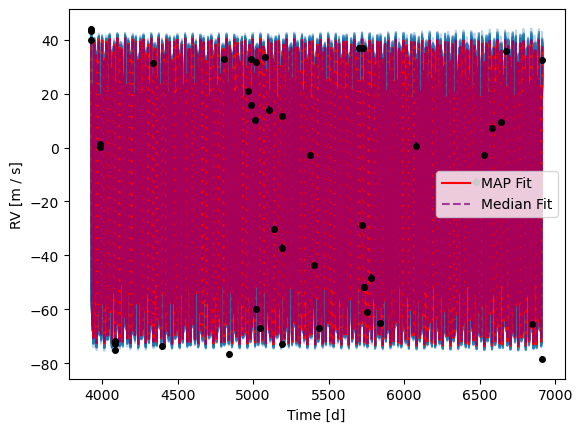

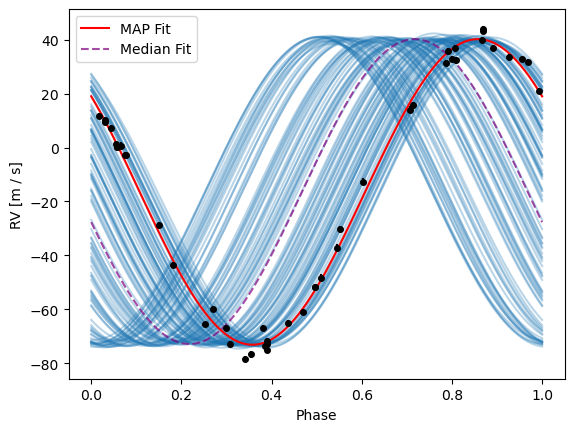

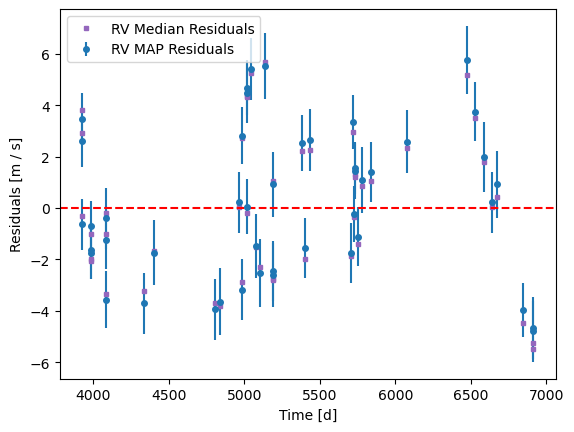

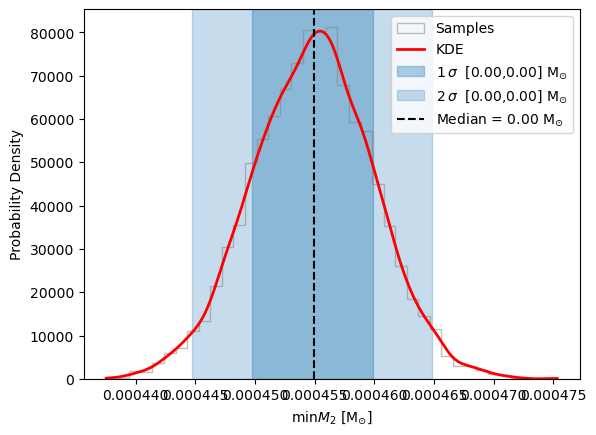

In [12]:
p.all_plots(results2,rv_data)

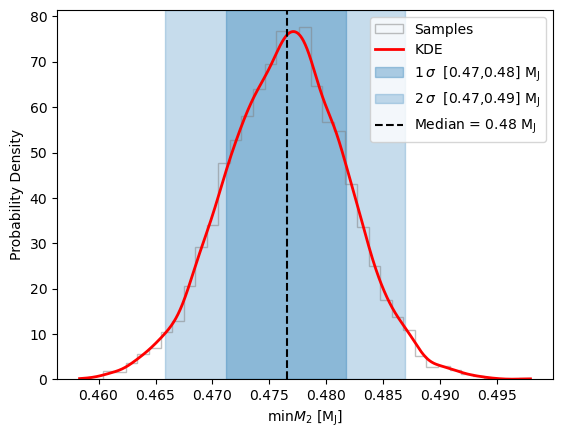

In [14]:
p.distribution(results2,'minM2',unit='Mjup');